# Milestone 5b: Making DQN work: experience replay and a target network

**Question:** Which stabiliser matters: replay, target network, or both?

**Setup:** identical network, reward, and 120k-step budget. Four variants x 3 seeds. Evaluation: greedy policy, 300 unseen episodes per run.

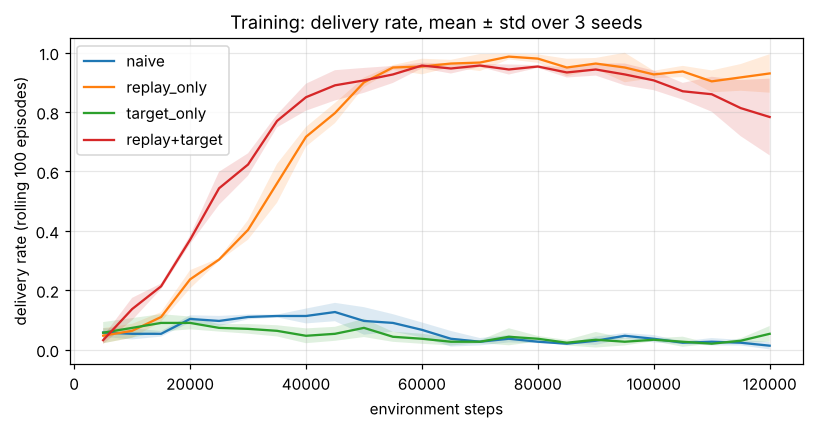

In [1]:
import sys, json; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src.warehouse_env import WarehouseEnv, evaluate_policy, MOVES
abl = json.load(open("../results/ablation.json"))
runs = pd.DataFrame([dict(variant=r["variant"], seed=r["seed"], **r["eval"]) for r in abl["runs"]])
order = ["naive", "replay_only", "target_only", "replay+target"]
fig, ax = plt.subplots(figsize=(7.5, 4))
grid = np.array(abl["grid"])
for v in order:
    c = np.array([r["curve"] for r in abl["runs"] if r["variant"] == v])
    m, s = c.mean(0), c.std(0)
    ax.plot(grid, m, label=v); ax.fill_between(grid, m - s, m + s, alpha=.15)
ax.set(xlabel="environment steps", ylabel="delivery rate (rolling 100 episodes)", title="Training: delivery rate, mean ± std over 3 seeds")
ax.legend(); plt.tight_layout(); plt.savefig("../docs/img/m5b_ablation.png"); plt.show()

In [2]:
summary = runs.groupby("variant").agg(["mean", "std"]).drop(columns="seed").round(3).loc[order]
print(summary.to_string())
summary.to_csv("../results/ablation_summary.csv")

              delivery_rate        collision_rate        bumps_per_episode        path_efficiency       
                       mean    std           mean    std              mean    std            mean    std
variant                                                                                                 
naive                 0.003  0.003          0.051  0.072             4.086  5.752           0.667  0.577
replay_only           0.456  0.086          0.001  0.002             0.074  0.129           0.988  0.004
target_only           0.016  0.012          0.000  0.000             0.000  0.000           0.969  0.028
replay+target         0.471  0.107          0.014  0.020             1.059  1.439           0.986  0.003


## Takeaways
- **Experience replay is the ingredient that matters here.** Delivery on 300 unseen episodes (mean ± std, 3 seeds): naive 0.3% ± 0.3, target-network-only 1.6% ± 1.2, replay-only 45.6% ± 8.6, replay + target 47.1% ± 10.7.
- Replay-only and replay + target are **statistically indistinguishable with 3 seeds**. Replay + target looks faster early in training, but its training curve drops late, so I would not claim the target network helps in this setup.
- A likely reason a target network alone does not help: consecutive, highly correlated samples remain the dominant problem. I did not test that explanation.
- Caveat: all training curves use 5% random actions, which flatters them (see notebook m5c).